# Model Terbaik Prediksi Kurs USD/IDR: Fine-Tuned Bi-LSTM Multimodal (Title-Only BERT, 32 Fitur)

Notebook ini merupakan **pipeline utuh (end-to-end) model terbaik** berbasis arsitektur **Fine-Tuned Bi-LSTM** dengan **embedding judul berbasis BERT-base saja** dan **sentimen berbasis FinBERT saja** (BERT finansial; model sentimen lain dihapus dari pipeline):
- **Arsitektur Model:** **Fine-Tuned Bi-LSTM** (`SeqLSTMRegressor`, `bidirectional=True`, `seq_len=10`, `hidden_dim=16`, `num_layers=1`, `dropout=0.5`, `input_noise=0.1`, `dir_lambda=0.15`, `lr=0.0005`, `weight_decay=0.05`, ensemble 5 seed).
- **Embedding Judul Only (BERT-based saja):** **`bert-base-uncased`** (*frozen* + PCA).
- **Subset Fitur Stage 2 (32 Fitur, tanpa fitur duplikat/redundan):**
  1. **14 Fitur Time Series Kausal ($\le t-1$)**: lagged return, volatilitas rolling, deviasi MA5/10/20, RSI-14, streak naik/turun, spread, dan encoding hari.
  2. **4 Fitur Embedding Judul BERT (`bert-base-uncased` frozen + PCA-4)**.
  3. **2 Fitur Sentimen FinBERT (`finbert_pos`, `finbert_neg`; `ProsusAI/finbert` frozen)**.
  4. **7 Fitur Interaksi `Sentimen × Arah` & OOF Stage 1**: `pred_dir_signed` dari `LogReg(C=0.1, d=8)` (OOF kronologis *expanding-window* di Train), `kurs_pressure`, `sent_magnitude`, `has_news`, `sent_x_dir`, `sent_mag_x_dir`, dan `sent_dir_5tier`.
  5. **5 Fitur Topik BERTopic (`all-MiniLM-L6-v2` frozen)**: PCA-3 + UMAP-2D.
  *(Catatan anti-overfit: fitur duplikat/turunan berlebih dibuang (45 → 32), OOF Stage 1 tidak lagi di-*shuffle*, model Bi-LSTM diperkecil dengan regularisasi kuat + ensemble multi-seed. Seluruh fitur sentimen kini bersumber dari FinBERT. Stage 1 `LogReg` memakai 23 fitur. Section 11 berisi ablation study per grup fitur.)*

Seluruh pipeline menerapkan **Strict Chronological Split (70% Train / 15% Val / 15% Test)** sejak awal untuk menjamin **zero data leakage**.

## 1. Setup Lingkungan & Seed Deterministik

In [1]:
!pip install -q bertopic  # Aktifkan jika dijalankan di environment baru (mis. Colab/Kaggle)

In [2]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["USE_TF"] = "0"

import gc
import re
import copy
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sentence_transformers import SentenceTransformer

from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed: int = SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
})
sns.set_style("whitegrid")

print(f"Device aktif : {DEVICE}")
print(f"PyTorch      : {torch.__version__}")

I0000 00:00:1795620103.085358      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Device aktif : cuda
PyTorch      : 2.11.0+cu130


## 2. Pemuatan Dataset & Split Kronologis di Awal (Zero Leakage)

Membaca `merged_data_clean.csv`, menghitung `rate_mid`, `log_ret`, dan target arah `y_dir` (`1 = Kurs Naik`, `0 = Kurs Turun`), lalu langsung melakukan split kronologis `70% Train / 15% Val / 15% Test` sebelum ekstraksi fitur parametrik apa pun.

In [3]:
DATA_CANDIDATES = [
    Path("data/processed/merged_data_clean.csv"),
    Path("../data/processed/merged_data_clean.csv"),
    Path("/kaggle/input/datasets/graceee12/process-dataset/processed/merged_data_clean.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Tidak menemukan data/processed/merged_data_clean.csv!")

df = pd.read_csv(DATA_PATH)
date_col = "Tanggal_dt" if "Tanggal_dt" in df.columns else "tanggal"
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

if "rate_mid" not in df.columns:
    df["rate_mid"] = (df["Kurs Jual"] + df["Kurs Beli"]) / 2.0

df["log_ret"] = np.log(df["rate_mid"] / df["rate_mid"].shift(1))
df = df.dropna(subset=["log_ret"]).reset_index(drop=True)
df["y_dir"] = (df["log_ret"] > 0).astype(int)

def clean_text_keep_case(text) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["title_clean"] = df["all_title"].fillna("").apply(clean_text_keep_case)
df["norm_clean"] = df["all_normalized_text"].fillna("").apply(clean_text_keep_case)
df["has_news"] = (df["news_count"].fillna(0) > 0).astype(int)

# SPLIT KRONOLOGIS DI AWAL (70% Train / 15% Val / 15% Test)
n_total = len(df)
train_end_idx = int(n_total * 0.70)
val_end_idx = int(n_total * 0.85)

df["split"] = "test"
df.loc[:train_end_idx - 1, "split"] = "train"
df.loc[train_end_idx:val_end_idx - 1, "split"] = "val"

train_end_date = df.loc[train_end_idx - 1, date_col]
val_end_date = df.loc[val_end_idx - 1, date_col]

is_tr = (df["split"] == "train").values
is_va = (df["split"] == "val").values
is_te = (df["split"] == "test").values

y_tr_dir = df.loc[is_tr, "y_dir"].values
y_va_dir = df.loc[is_va, "y_dir"].values
y_te_dir = df.loc[is_te, "y_dir"].values

print(f"Data path: {DATA_PATH}")
print(f"Dataset  : {n_total:,} hari perdagangan valid")
for sp, m in [("Train", is_tr), ("Val", is_va), ("Test", is_te)]:
    sub = df.loc[m]
    print(
        f"  {sp:5s}: {len(sub):4d} hari | {sub[date_col].min().date()} s/d {sub[date_col].max().date()} "
        f"| Naik={sub['y_dir'].mean()*100:.1f}% | Ada Berita={sub['has_news'].mean()*100:.1f}%"
    )

Data path: /kaggle/input/datasets/graceee12/process-dataset/processed/merged_data_clean.csv
Dataset  : 1,201 hari perdagangan valid
  Train:  840 hari | 2021-09-02 s/d 2025-02-18 | Naik=55.4% | Ada Berita=86.1%
  Val  :  180 hari | 2025-02-19 s/d 2025-11-21 | Naik=53.3% | Ada Berita=88.9%
  Test :  181 hari | 2025-11-24 s/d 2026-09-01 | Naik=57.5% | Ada Berita=97.8%


## 3. Embedding Judul Only (Frozen Layer): BERT-base + PCA

- Ekstraksi embedding judul berita (`title_clean`, `max_length=48`) hanya menggunakan **`bert-base-uncased`** dengan bobot pre-trained **frozen**.
- `StandardScaler` + `PCA(n_components=8)` di-fit **hanya pada Train set (`is_tr`)** lalu ditransformasikan ke Val dan Test.

In [4]:
import os
import gc
import numpy as np
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


def extract_daily_title_embeddings(
    model_name: str,
    unique_titles: list,
    title_lists,
    batch_size: int = 128,
    max_len: int = 48,
    cache_path: str = None,
):
    # Cache: lewati komputasi bila sudah pernah dihitung
    if cache_path and os.path.exists(cache_path):
        print(f"Memuat cache embedding dari {cache_path}")
        data = np.load(cache_path, allow_pickle=True)
        title_emb_map = dict(zip(data["titles"].tolist(), data["embs"]))
    else:
        print(f"Memuat frozen model untuk embedding judul: {model_name} (device={DEVICE}) ...")
        tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
        mdl = AutoModel.from_pretrained(model_name).to(DEVICE)
        mdl.eval()
        for p in mdl.parameters():
            p.requires_grad = False

        use_amp = (str(DEVICE).startswith("cuda"))

        # Urutkan berdasarkan panjang agar padding minimal (jauh lebih cepat)
        order = sorted(range(len(unique_titles)), key=lambda i: len(unique_titles[i]))
        sorted_titles = [unique_titles[i] for i in order]

        title_emb_map = {}
        with torch.inference_mode():
            for i in tqdm(range(0, len(sorted_titles), batch_size), desc="Embedding judul"):
                batch_txt = sorted_titles[i : i + batch_size]
                enc = tok(
                    batch_txt,
                    padding=True,
                    truncation=True,
                    max_length=max_len,
                    return_tensors="pt",
                ).to(DEVICE)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                    out = mdl(**enc).last_hidden_state
                out = out.float()
                mask = enc["attention_mask"].unsqueeze(-1).float()
                emb = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
                emb_np = emb.cpu().numpy()
                for t_str, vec in zip(batch_txt, emb_np):
                    title_emb_map[t_str] = vec

        del mdl, tok
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        if cache_path:
            np.savez(
                cache_path,
                titles=np.array(list(title_emb_map.keys()), dtype=object),
                embs=np.stack(list(title_emb_map.values())),
            )
            print(f"Cache disimpan ke {cache_path}")

    hidden_dim = next(iter(title_emb_map.values())).shape[0]
    daily_emb = np.zeros((len(title_lists), hidden_dim), dtype=np.float32)
    for row_idx, t_list in enumerate(title_lists):
        if t_list:
            daily_emb[row_idx] = np.mean([title_emb_map[t] for t in t_list], axis=0)
    return daily_emb


title_lists = [[p.strip() for p in s.split(" | ") if p.strip()] for s in df["title_clean"]]
unique_titles = sorted({t for sub in title_lists for t in sub})
print(f"Total judul unik: {len(unique_titles):,} | Hari dengan berita: {int(df['has_news'].sum())}/{len(df)}")

# Frozen BERT-base Title Embedding
BERT_MODEL_NAME = "bert-base-uncased"
daily_bert_title = extract_daily_title_embeddings(
    BERT_MODEL_NAME,
    unique_titles,
    title_lists,
    batch_size=128,
    max_len=48,
    cache_path="bert_title_emb_cache.npz",
)
print(f"BERT Title daily matrix: {daily_bert_title.shape}")

N_PCA_BERT = 8
# Fit scaler & PCA hanya pada data train (hindari leakage)
sc_bert = StandardScaler().fit(daily_bert_title[is_tr])
pca_bert = PCA(n_components=N_PCA_BERT, random_state=SEED).fit(sc_bert.transform(daily_bert_title[is_tr]))
bert_pca_feats = pca_bert.transform(sc_bert.transform(daily_bert_title))
bert_pca_cols = [f"bert_pca_{i}" for i in range(N_PCA_BERT)]
for i, c in enumerate(bert_pca_cols):
    df[c] = bert_pca_feats[:, i].astype(np.float32)

print(f"PCA Var Explained -> BERT-Title ({N_PCA_BERT}): {pca_bert.explained_variance_ratio_.sum():.3f}")

Total judul unik: 3,923 | Hari dengan berita: 1060/1201
Memuat frozen model untuk embedding judul: bert-base-uncased (device=cuda) ...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding judul:   0%|          | 0/31 [00:00<?, ?it/s]

Cache disimpan ke bert_title_emb_cache.npz
BERT Title daily matrix: (1201, 768)
PCA Var Explained -> BERT-Title (8): 0.451


## 4. Analisis Sentimen Finansial (Frozen FinBERT)

Logika kurs **USD/IDR**:
- Berita negatif $\rightarrow$ `kurs_pressure = P(neg) - P(pos) > 0` (USD/IDR naik / Rupiah melemah).
- Berita positif $\rightarrow$ `kurs_pressure < 0` (USD/IDR turun / Rupiah menguat).

Sentimen hanya diekstrak dari **`ProsusAI/finbert`** (frozen) dan dipakai sebagai input **Stage 1 (`LogReg`)**, sumber fitur `Sent×Arah`, serta 5 fitur `GRP_FINBERT_SENT` di Stage 2. Tidak ada lagi seleksi sumber sentimen berbasis Validation Set.

In [5]:
def extract_daily_sentiment(model_name: str, unique_titles: list[str], title_lists, prefix: str, batch_size: int = 64, max_len: int = 64):
    print(f"Memuat frozen sentiment model: {model_name} ...")
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEVICE)
    mdl.eval()
    for p in mdl.parameters():
        p.requires_grad = False

    id2lbl = {int(k): v.lower() for k, v in mdl.config.id2label.items()}
    print(f"  -> id2label ({prefix}): {id2lbl}")
    pos_idx = next(k for k, v in id2lbl.items() if ("pos" in v) or ("bull" in v))
    neg_idx = next(k for k, v in id2lbl.items() if ("neg" in v) or ("bear" in v))
    neu_idx = next(k for k, v in id2lbl.items() if "neu" in v)

    sent_map = {}
    with torch.no_grad():
        for i in range(0, len(unique_titles), batch_size):
            batch_txt = unique_titles[i : i + batch_size]
            enc = tok(batch_txt, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
            logits = mdl(**enc).logits
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
            for t_str, pr in zip(batch_txt, probs):
                sent_map[t_str] = (float(pr[pos_idx]), float(pr[neg_idx]), float(pr[neu_idx]))

    del mdl, tok
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    daily_pos = np.zeros(len(title_lists), dtype=np.float32)
    daily_neg = np.zeros(len(title_lists), dtype=np.float32)
    daily_neu = np.zeros(len(title_lists), dtype=np.float32)
    for row_idx, t_list in enumerate(title_lists):
        if t_list:
            arr = np.array([sent_map[t] for t in t_list], dtype=np.float32)
            daily_pos[row_idx], daily_neg[row_idx], daily_neu[row_idx] = arr.mean(axis=0)
        else:
            daily_neu[row_idx] = 1.0

    kp = (daily_neg - daily_pos).astype(np.float32)
    sp = (daily_pos - daily_neg).astype(np.float32)
    smag = np.abs(kp).astype(np.float32)
    srat = (daily_neg / (daily_pos + daily_neg + 1e-6)).astype(np.float32)

    return {
        f"{prefix}_pos": daily_pos,
        f"{prefix}_neg": daily_neg,
        f"{prefix}_neu": daily_neu,
        f"{prefix}_kurs_pressure": kp,
        f"{prefix}_sent_polarity": sp,
        f"{prefix}_sent_magnitude": smag,
        f"{prefix}_sent_ratio": srat,
    }


fin_dict = extract_daily_sentiment("ProsusAI/finbert", unique_titles, title_lists, prefix="finbert", batch_size=64, max_len=64)
for k, v in fin_dict.items():
    df[k] = v

fin_cont_cols = [
    "finbert_kurs_pressure", "finbert_sent_polarity", "finbert_sent_magnitude",
    "finbert_sent_ratio", "finbert_pos", "finbert_neg", "finbert_neu", "has_news",
]

# FinBERT jadi satu-satunya sumber sentimen (tanpa seleksi berbasis Val)
PRIMARY_SENT_SRC = "FinBERT"
df["kurs_pressure"]  = df["finbert_kurs_pressure"]
df["sent_polarity"]  = df["finbert_sent_polarity"]
df["sent_magnitude"] = df["finbert_sent_magnitude"]
df["sent_ratio"]     = df["finbert_sent_ratio"]
print(f"Sumber sentimen: {PRIMARY_SENT_SRC}")


Memuat frozen sentiment model: ProsusAI/finbert ...


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  -> id2label (finbert): {0: 'positive', 1: 'negative', 2: 'neutral'}
Sumber sentimen: FinBERT


## 5. Topic Modelling BERTopic + Reduksi Dimensi (PCA-5 & UMAP-2D, Fit di Train Saja)

In [6]:
try:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE, local_files_only=True)
except Exception:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
for p in st_model.parameters():
    p.requires_grad = False
st_model.eval()

daily_topic_docs = [
    f"{t}. {b[:500]}".strip() if hn == 1 else ""
    for t, b, hn in zip(df["title_clean"], df["norm_clean"], df["has_news"])
]
news_mask = df["has_news"].values == 1
tr_news_mask = is_tr & news_mask
news_docs_all = [d for d, m in zip(daily_topic_docs, news_mask) if m]

with torch.no_grad():
    news_embs_all = st_model.encode(news_docs_all, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

emb_minilm_full = np.zeros((len(df), news_embs_all.shape[1]), dtype=np.float32)
emb_minilm_full[news_mask] = news_embs_all

tr_docs = [daily_topic_docs[i] for i in np.where(tr_news_mask)[0]]
tr_embs = emb_minilm_full[tr_news_mask]

umap_bt = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
hdbscan_bt = HDBSCAN(min_cluster_size=15, min_samples=5, metric="euclidean", cluster_selection_method="eom", prediction_data=True)
vec_bt = CountVectorizer(stop_words="english", min_df=3, ngram_range=(1, 2))

topic_model = BERTopic(
    embedding_model=st_model,
    umap_model=umap_bt,
    hdbscan_model=hdbscan_bt,
    vectorizer_model=vec_bt,
    calculate_probabilities=True,
    verbose=False,
)
tr_topics, _ = topic_model.fit_transform(tr_docs, tr_embs)
bt_info = topic_model.get_topic_info()
print(f"BERTopic di-fit pada {len(tr_docs)} hari Train berberita -> {int((bt_info['Topic'] != -1).sum())} topik.")
display(bt_info.head(10))

all_news_topics, all_news_probs = topic_model.transform(news_docs_all, emb_minilm_full[news_mask])
all_news_probs = np.asarray(all_news_probs)
if all_news_probs.ndim == 1:
    uniq_t = sorted([t for t in set(tr_topics) if t != -1])
    oh = np.zeros((len(all_news_topics), max(len(uniq_t), 1)), dtype=np.float32)
    tmap = {t: j for j, t in enumerate(uniq_t)}
    for r_i, tv in enumerate(all_news_topics):
        if tv in tmap:
            oh[r_i, tmap[tv]] = 1.0
    all_news_probs = oh

topic_prob_full = np.zeros((len(df), all_news_probs.shape[1]), dtype=np.float32)
topic_prob_full[news_mask] = all_news_probs
df["bt_topic"] = -2
df.loc[news_mask, "bt_topic"] = all_news_topics

# Reduksi dimensi probabilitas topik dengan PCA-5 (fit di Train)
TOPIC_PCA_DIM = min(5, topic_prob_full.shape[1])
sc_top = StandardScaler().fit(topic_prob_full[is_tr])
pca_top = PCA(n_components=TOPIC_PCA_DIM, random_state=SEED).fit(sc_top.transform(topic_prob_full[is_tr]))
top_pca = pca_top.transform(sc_top.transform(topic_prob_full))
topic_pca_cols = [f"topic_pca_{i}" for i in range(TOPIC_PCA_DIM)]
for i, c in enumerate(topic_pca_cols):
    df[c] = top_pca[:, i]

# Reduksi dimensi UMAP 2D (fit di Train berberita)
umap_2d = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=SEED).fit(tr_embs)
umap_2d_news = umap_2d.transform(emb_minilm_full[news_mask])
df["topic_umap_0"], df["topic_umap_1"] = 0.0, 0.0
df.loc[news_mask, "topic_umap_0"] = umap_2d_news[:, 0]
df.loc[news_mask, "topic_umap_1"] = umap_2d_news[:, 1]
topic_umap_cols = ["topic_umap_0", "topic_umap_1"]

del st_model
gc.collect()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

BERTopic di-fit pada 723 hari Train berberita -> 6 topik.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,179,-1_oil_biden_iran_says,"[oil, biden, iran, says, dollar, climate, new,...",[Arch-rivals Iran and Saudi Arabia agree to re...
1,0,288,0_china_says_market_ceo,"[china, says, market, ceo, beijing, new, cnbc,...",[5 things to know before the stock market open...
2,1,122,1_ukraine_russia_putin_russian,"[ukraine, russia, putin, russian, war, moscow,...",[Freedom will prevail in Ukraine | Next 24 hou...
3,2,40,2_israel_gaza_israeli_hamas,"[israel, gaza, israeli, hamas, palestinian, wa...",[Israel and Hezbollah carry out new attacks am...
4,3,39,3_oil_crude_oil prices_prices,"[oil, crude, oil prices, prices, crude oil, mi...",[U.S. crude oil breaks $86 as tensions mount b...
5,4,35,4_treasury_bank_inflation_rates,"[treasury, bank, inflation, rates, yield, engl...","[Bank of England hikes rates again, adopts dov..."
6,5,20,5_ukraine_russia_talks_biden,"[ukraine, russia, talks, biden, russian, war, ...",[Saudi Arabia and Turkey are emerging as the n...


122735

## 6. Stage 1 Classifier Arah Return (`LogReg(C=0.1, d=8)`) + OOF Kronologis (Expanding Window)

Menggunakan embedding judul **BERT-base saja (`bert_pca_0..7`)**, fitur sentimen FinBERT, dan fitur topik BERTopic (total 23 fitur) dengan **Out-Of-Fold (OOF) kronologis *expanding-window* (`TimeSeriesSplit`, tanpa shuffle)** di Train Set untuk mencegah *leakage* temporal ke Stage 2. Blok awal Train yang belum punya data historis diberi probabilitas netral 0.5 (`pred_dir_signed = 0`).

In [7]:
stage1_cols = bert_pca_cols[:8] + fin_cont_cols + topic_pca_cols + topic_umap_cols  # 23 fitur
def make_best_s1():
    return LogisticRegression(C=0.1, class_weight="balanced", max_iter=1000, random_state=SEED)

# OOF kronologis (expanding window, tanpa shuffle): fold hanya dilatih dari masa lalu -> tidak ada kebocoran temporal
X_s1_tr = df.loc[is_tr, stage1_cols].reset_index(drop=True)
oof_tr_prob = np.full(len(y_tr_dir), 0.5, dtype=np.float64)   # 0.5 = netral untuk blok awal tanpa histori
oof_mask = np.zeros(len(y_tr_dir), dtype=bool)
for tr_f, ho_f in TimeSeriesSplit(n_splits=5).split(X_s1_tr):
    sc_f = StandardScaler().fit(X_s1_tr.iloc[tr_f])
    clf_f = make_best_s1().fit(sc_f.transform(X_s1_tr.iloc[tr_f]), y_tr_dir[tr_f])
    oof_tr_prob[ho_f] = clf_f.predict_proba(sc_f.transform(X_s1_tr.iloc[ho_f]))[:, 1]
    oof_mask[ho_f] = True

sc_s1 = StandardScaler().fit(df.loc[is_tr, stage1_cols])
final_s1 = make_best_s1().fit(sc_s1.transform(df.loc[is_tr, stage1_cols]), y_tr_dir)
p_s1_va = final_s1.predict_proba(sc_s1.transform(df.loc[is_va, stage1_cols]))[:, 1]
p_s1_te = final_s1.predict_proba(sc_s1.transform(df.loc[is_te, stage1_cols]))[:, 1]

df.loc[is_tr, "pred_dir_prob"] = oof_tr_prob
df.loc[is_va, "pred_dir_prob"] = p_s1_va
df.loc[is_te, "pred_dir_prob"] = p_s1_te
df["pred_dir_class"] = (df["pred_dir_prob"] >= 0.5).astype(int)
df["pred_dir_signed"] = 2.0 * df["pred_dir_prob"] - 1.0

s1_eval_df = pd.DataFrame([
    {"Split": "Train (OOF kronologis)", "Acc (%)": round(accuracy_score(y_tr_dir[oof_mask], (oof_tr_prob[oof_mask] >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_tr_dir[oof_mask], (oof_tr_prob[oof_mask] >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_tr_dir[oof_mask], oof_tr_prob[oof_mask]), 4)},
    {"Split": "Validation", "Acc (%)": round(accuracy_score(y_va_dir, (p_s1_va >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_s1_va >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_va_dir, p_s1_va), 4)},
    {"Split": "Test", "Acc (%)": round(accuracy_score(y_te_dir, (p_s1_te >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_te_dir, (p_s1_te >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_te_dir, p_s1_te), 4)},
])
print(f"Stage 1 Model: LogReg(C=0.1, d=8) ({len(stage1_cols)} fitur)")
display(s1_eval_df)

Stage 1 Model: LogReg(C=0.1, d=8) (23 fitur)


,Split,Acc (%),BalAcc (%),ROC-AUC
0,Train (OOF kronologis),52.00,52.07,0.5173
1,Validation,45.56,45.46,0.4508
2,Test,50.28,48.30,0.5012


## 7. Fitur Interaksi `Sentimen × Arah` (Q70 & Q90 Train)

In [8]:
tr_mags = df.loc[is_tr & (df["has_news"] == 1), "sent_magnitude"].values
HIGH_SENT_THRES = float(np.quantile(tr_mags, 0.70))
EXTREME_SENT_THRES = float(np.quantile(tr_mags, 0.90))
print(f"Ambang Sentimen Tinggi  (Q70 Train): {HIGH_SENT_THRES:.4f}")
print(f"Ambang Sentimen Ekstrem (Q90 Train): {EXTREME_SENT_THRES:.4f}")

df["sent_x_dir"] = df["kurs_pressure"] * df["pred_dir_signed"]
df["sent_mag_x_dir"] = df["sent_magnitude"] * df["pred_dir_signed"]
df["extreme_amp_x_dir"] = np.sign(df["sent_x_dir"]) * (np.abs(df["sent_x_dir"]) ** 2)

dir_up = df["pred_dir_signed"] > 0
dir_dn = df["pred_dir_signed"] < 0   # baris netral (prob=0.5) tidak dapat flag arah
is_high = df["sent_magnitude"] >= HIGH_SENT_THRES
is_ext = df["sent_magnitude"] >= EXTREME_SENT_THRES

df["flag_naik_sent_tinggi"] = (dir_up & is_high).astype(int)
df["flag_turun_sent_tinggi"] = (dir_dn & is_high).astype(int)
df["flag_naik_ekstrem"] = (dir_up & is_ext).astype(int)
df["flag_turun_ekstrem"] = (dir_dn & is_ext).astype(int)

df["extreme_turun_pressure"] = df["flag_turun_ekstrem"] * (-df["sent_magnitude"])
df["extreme_naik_pressure"] = df["flag_naik_ekstrem"] * (df["sent_magnitude"])

df["sent_dir_5tier"] = (
    df["flag_naik_sent_tinggi"] + df["flag_naik_ekstrem"]
    - df["flag_turun_sent_tinggi"] - df["flag_turun_ekstrem"]
)

Ambang Sentimen Tinggi  (Q70 Train): 0.4587
Ambang Sentimen Ekstrem (Q90 Train): 0.8343


## 8. Fitur Time Series Kausal ($\le t-1$) & Seleksi 32 Fitur (BERT Title Only)

Menyusun 14 fitur *time series* kausal dan menggabungkannya dengan **embedding judul BERT saja** (tanpa 5 fitur sentimen mentah dari model sentimen non-FinBERT) sehingga totalnya **32 fitur** (fitur duplikat seperti `finbert_kurs_pressure` ≡ `kurs_pressure` dan flag/tier yang redundan dibuang untuk menurunkan risiko overfitting; 811 sampel Train tidak cukup untuk 45 fitur yang saling berkorelasi) untuk input sekuensial `Bi-LSTM` (`seq_len = 10`).

In [9]:
df["ret_lag1"] = df["log_ret"].shift(1)
df["ret_lag2"] = df["log_ret"].shift(2)
df["ret_lag3"] = df["log_ret"].shift(3)
df["ret_lag5"] = df["log_ret"].shift(5)
df["vol_5d"] = df["log_ret"].shift(1).rolling(5).std()
df["vol_10d"] = df["log_ret"].shift(1).rolling(10).std()

for w in [5, 10, 20]:
    ma_w = df["rate_mid"].shift(1).rolling(w).mean()
    df[f"dist_ma{w}"] = df["rate_mid"].shift(1) / ma_w - 1.0

delta = df["rate_mid"].diff().shift(1)
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
df["rsi_14"] = (100.0 - (100.0 / (1.0 + gain / (loss + 1e-9)))) / 100.0

consecs, cur = [], 0
for r in df["log_ret"]:
    cur = (cur + 1 if cur > 0 else 1) if r > 0 else ((cur - 1 if cur < 0 else -1) if r < 0 else 0)
    consecs.append(cur)
df["consec_up_days"] = pd.Series(consecs, index=df.index).shift(1)
df["spread_lag1"] = ((df["Kurs Jual"] - df["Kurs Beli"]) / df["rate_mid"]).shift(1)
dow = df[date_col].dt.dayofweek
df["dow_sin"] = np.sin(2 * np.pi * dow / 5.0)
df["dow_cos"] = np.cos(2 * np.pi * dow / 5.0)

# Definisi 5 kelompok fitur terpilih (BERT Title Only, tanpa 5 fitur mentah sentimen non-FinBERT)
GRP_TS = [
    "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag5",
    "vol_5d", "vol_10d", "dist_ma5", "dist_ma10", "dist_ma20",
    "rsi_14", "consec_up_days", "spread_lag1", "dow_sin", "dow_cos",
]
GRP_BERT_TITLE = bert_pca_cols[:4]
GRP_FINBERT_SENT = ["finbert_pos", "finbert_neg"]  # neu dibuang (kolinear: pos+neg+neu ≈ 1); kurs_pressure & magnitude sudah ada di GRP_SENT_INTER
GRP_SENT_INTER = [
    "kurs_pressure", "sent_magnitude", "has_news",
    "pred_dir_signed",
    "sent_x_dir", "sent_mag_x_dir",
    "sent_dir_5tier",
]
GRP_BERTOPIC = topic_pca_cols[:3] + topic_umap_cols

BEST_COLS = GRP_TS + GRP_BERT_TITLE + GRP_FINBERT_SENT + GRP_SENT_INTER + GRP_BERTOPIC
assert len(BEST_COLS) == 32, f"Expected 32 fitur, got {len(BEST_COLS)}"
assert len(set(BEST_COLS)) == len(BEST_COLS), "Ada fitur duplikat di BEST_COLS"

df_model = df.dropna(subset=BEST_COLS + ["log_ret"]).reset_index(drop=True)
m_tr = (df_model[date_col] <= train_end_date).values
m_va = ((df_model[date_col] > train_end_date) & (df_model[date_col] <= val_end_date)).values
m_te = (df_model[date_col] > val_end_date).values

print(f"Baris valid Stage 2: {len(df_model):,} | Train={m_tr.sum()}, Val={m_va.sum()}, Test={m_te.sum()}")
print(
    f"Total Fitur Terpilih: {len(BEST_COLS)} "
    f"(TS={len(GRP_TS)}, BERT-Title={len(GRP_BERT_TITLE)}, "
    f"FinBERT={len(GRP_FINBERT_SENT)}, Sent×Arah={len(GRP_SENT_INTER)}, BERTopic={len(GRP_BERTOPIC)})"
)

def build_sequences(frame: pd.DataFrame, feature_cols: list[str], seq_len: int):
    sc_x = StandardScaler().fit(frame.loc[m_tr, feature_cols])
    X_scaled = sc_x.transform(frame[feature_cols]).astype(np.float32)
    y_raw = frame["log_ret"].values.astype(np.float32)
    mu_y = float(y_raw[m_tr].mean())
    std_y = float(y_raw[m_tr].std() + 1e-9)
    y_scaled = ((y_raw - mu_y) / std_y).astype(np.float32)

    X_seqs, y_seqs_s, y_seqs_raw, seq_splits, seq_dates, prev_rates, curr_rates = [], [], [], [], [], [], []
    split_arr = np.where(m_tr, "train", np.where(m_va, "val", "test"))
    dates_arr = frame[date_col].values
    rates_arr = frame["rate_mid"].values

    for t in range(seq_len - 1, len(frame)):
        X_seqs.append(X_scaled[t - seq_len + 1 : t + 1])
        y_seqs_s.append(y_scaled[t])
        y_seqs_raw.append(y_raw[t])
        seq_splits.append(split_arr[t])
        seq_dates.append(dates_arr[t])
        prev_rates.append(rates_arr[t - 1])
        curr_rates.append(rates_arr[t])

    return {
        "X": np.array(X_seqs, dtype=np.float32),
        "y_s": np.array(y_seqs_s, dtype=np.float32),
        "y_raw": np.array(y_seqs_raw, dtype=np.float32),
        "split": np.array(seq_splits),
        "dates": pd.to_datetime(seq_dates),
        "prev_rate": np.array(prev_rates, dtype=np.float64),
        "curr_rate": np.array(curr_rates, dtype=np.float64),
        "mu_y": mu_y,
        "std_y": std_y,
        "scaler_x": sc_x,
    }

BEST_SEQ_LEN = 10
seq_data = build_sequences(df_model, BEST_COLS, seq_len=BEST_SEQ_LEN)
sp = seq_data["split"]
print(f"Shape sequence X: {seq_data['X'].shape} | Train={(sp=='train').sum()}, Val={(sp=='val').sum()}, Test={(sp=='test').sum()}")

Baris valid Stage 2: 1,181 | Train=820, Val=180, Test=181
Total Fitur Terpilih: 32 (TS=14, BERT-Title=4, FinBERT=2, Sent×Arah=7, BERTopic=5)
Shape sequence X: (1172, 10, 32) | Train=811, Val=180, Test=181


## 9. Pelatihan & Evaluasi Model Terbaik (`Fine-Tuned Bi-LSTM`, 32 Fitur)

Melatih arsitektur **`SeqLSTMRegressor` (`bidirectional=True`)** dengan konfigurasi **anti-overfit** (`seq_len=10`, `hidden_dim=16`, `num_layers=1`, `dropout=0.5`, noise & dropout input 0.1, `dir_lambda=0.15`, `lr=0.0005`, `weight_decay=0.05`, early stopping pada Val, **ensemble 5 seed**) dan membandingkannya dengan baseline pada **Train, Validation, dan Test Set**.

In [10]:
class SeqLSTMRegressor(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 16, num_layers: int = 1,
                 dropout: float = 0.5, bidirectional: bool = True,
                 input_noise: float = 0.1, input_dropout: float = 0.1):
        super().__init__()
        self.input_noise = input_noise
        self.in_norm = nn.LayerNorm(input_dim)
        self.in_drop = nn.Dropout(input_dropout)
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.head = nn.Sequential(
            nn.LayerNorm(out_dim),
            nn.Dropout(dropout),
            nn.Linear(out_dim, 8),
            nn.Tanh(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(8, 1),
        )

    def forward(self, x):
        x = self.in_norm(x)
        if self.training and self.input_noise > 0:
            x = x + self.input_noise * torch.randn_like(x)  # augmentasi noise (hanya saat training)
        x = self.in_drop(x)
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_pytorch_regressor(model: nn.Module, X_tr_np, y_tr_s_np, X_va_np, y_va_s_np, X_te_np,
                            mu_y: float, std_y: float, lr: float = 5e-4, weight_decay: float = 5e-2,
                            dir_lambda: float = 0.15, batch_size: int = 64, epochs: int = 100,
                            patience: int = 10, seed: int = None):
    set_seed(SEED if seed is None else seed)
    X_tr = torch.tensor(X_tr_np, dtype=torch.float32)
    y_tr = torch.tensor(y_tr_s_np, dtype=torch.float32)
    X_tr_dev = X_tr.to(DEVICE)
    X_va = torch.tensor(X_va_np, dtype=torch.float32).to(DEVICE)
    y_va = torch.tensor(y_va_s_np, dtype=torch.float32).to(DEVICE)
    X_te = torch.tensor(X_te_np, dtype=torch.float32).to(DEVICE)

    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    def composite_loss(pred_s, target_s):
        mse = nn.functional.mse_loss(pred_s, target_s)
        zero_s = -mu_y / std_y
        sign_hinge = torch.relu(-(pred_s - zero_s) * torch.sign(target_s - zero_s)).mean()
        return mse + dir_lambda * sign_hinge

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    wait = 0
    tr_hist, va_hist = [], []

    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = composite_loss(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

        # Loss Train & Val dihitung dengan cara yang sama (mode eval, tanpa dropout/noise)
        model.eval()
        with torch.no_grad():
            tr_loss = float(composite_loss(model(X_tr_dev), y_tr.to(DEVICE)).item())
            va_loss = float(composite_loss(model(X_va), y_va).item())
        tr_hist.append(tr_loss)
        va_hist.append(va_loss)

        if va_loss < best_val_loss - 1e-6:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = ep + 1
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred_tr_raw = model(X_tr_dev).cpu().numpy() * std_y + mu_y
        pred_va_raw = model(X_va).cpu().numpy() * std_y + mu_y
        pred_te_raw = model(X_te).cpu().numpy() * std_y + mu_y

    return {
        "model": model,
        "pred_tr": pred_tr_raw,
        "pred_va": pred_va_raw,
        "pred_te": pred_te_raw,
        "tr_hist": tr_hist,
        "va_hist": va_hist,
        "best_epoch": best_epoch,
    }


def eval_reg(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    dt, dp = (y_true > 0).astype(int), (y_pred > 0).astype(int)
    return {
        "Model / Split": name,
        "RMSE": round(rmse, 6),
        "MAE": round(mae, 6),
        "R2": round(r2, 4),
        "DirAcc (%)": round(float(accuracy_score(dt, dp) * 100), 2),
        "BalAcc (%)": round(float(balanced_accuracy_score(dt, dp) * 100), 2),
        "F1-Macro (%)": round(float(f1_score(dt, dp, average="macro") * 100), 2),
    }


# Konfigurasi anti-overfit: model kecil, regularisasi kuat, early stopping, ensemble multi-seed
BEST_CFG = {
    "seq_len": 10,
    "hidden_dim": 16,
    "num_layers": 1,
    "dropout": 0.5,
    "bidirectional": True,
    "input_noise": 0.1,
    "input_dropout": 0.1,
    "dir_lambda": 0.15,
    "lr": 0.0005,
    "weight_decay": 0.05,
    "batch_size": 64,
    "epochs": 100,
    "patience": 10,
}
ENS_SEEDS = (42, 7, 123, 2024, 99)


def make_lstm(input_dim: int) -> SeqLSTMRegressor:
    return SeqLSTMRegressor(
        input_dim=input_dim,
        hidden_dim=BEST_CFG["hidden_dim"],
        num_layers=BEST_CFG["num_layers"],
        dropout=BEST_CFG["dropout"],
        bidirectional=BEST_CFG["bidirectional"],
        input_noise=BEST_CFG["input_noise"],
        input_dropout=BEST_CFG["input_dropout"],
    )


def train_ensemble(X_tr, y_tr_s, X_va, y_va_s, X_te, mu_y, std_y, seeds=ENS_SEEDS):
    """Latih model yang sama dengan beberapa seed lalu rata-ratakan prediksi (menurunkan varians)."""
    runs = [
        train_pytorch_regressor(
            make_lstm(X_tr.shape[-1]), X_tr, y_tr_s, X_va, y_va_s, X_te, mu_y, std_y,
            lr=BEST_CFG["lr"], weight_decay=BEST_CFG["weight_decay"], dir_lambda=BEST_CFG["dir_lambda"],
            batch_size=BEST_CFG["batch_size"], epochs=BEST_CFG["epochs"], patience=BEST_CFG["patience"], seed=s,
        )
        for s in seeds
    ]
    return {
        "runs": runs,
        "pred_tr": np.mean([r["pred_tr"] for r in runs], axis=0),
        "pred_va": np.mean([r["pred_va"] for r in runs], axis=0),
        "pred_te": np.mean([r["pred_te"] for r in runs], axis=0),
        "tr_hist": runs[0]["tr_hist"],   # kurva loss ditampilkan dari seed pertama
        "va_hist": runs[0]["va_hist"],
        "best_epoch": runs[0]["best_epoch"],
        "best_epochs_all": [r["best_epoch"] for r in runs],
    }


tr_m, va_m, te_m = sp == "train", sp == "val", sp == "test"
res_best = train_ensemble(
    seq_data["X"][tr_m], seq_data["y_s"][tr_m],
    seq_data["X"][va_m], seq_data["y_s"][va_m],
    seq_data["X"][te_m],
    seq_data["mu_y"], seq_data["std_y"],
)

y_tr_true = seq_data["y_raw"][tr_m]
y_va_true = seq_data["y_raw"][va_m]
y_te_true = seq_data["y_raw"][te_m]
mu_train_raw = float(y_tr_true.mean())

TEST_ROW_LABEL = f"Bi-LSTM Best (Test Set — {len(BEST_COLS)} Fitur)"
eval_summary_df = pd.DataFrame([
    eval_reg("Baseline Test: Tebak Return 0", y_te_true, np.zeros_like(y_te_true)),
    eval_reg("Baseline Test: Mean Train", y_te_true, np.full_like(y_te_true, mu_train_raw)),
    eval_reg("Bi-LSTM Best (Train Set)", y_tr_true, res_best["pred_tr"]),
    eval_reg("Bi-LSTM Best (Validation Set)", y_va_true, res_best["pred_va"]),
    eval_reg(TEST_ROW_LABEL, y_te_true, res_best["pred_te"]),
]).set_index("Model / Split")

print(f"Best Epoch per seed {ENS_SEEDS}: {res_best['best_epochs_all']}")
print(f"=== EVALUASI MODEL TERBAIK (FINE-TUNED BI-LSTM ENSEMBLE {len(ENS_SEEDS)} SEED, BERT TITLE ONLY, {len(BEST_COLS)} FITUR) ===")
display(eval_summary_df)

# Diagnostik overfitting: selisih Train vs Val/Test (makin kecil makin baik)
_tr = eval_summary_df.loc["Bi-LSTM Best (Train Set)"]
_va = eval_summary_df.loc["Bi-LSTM Best (Validation Set)"]
_te = eval_summary_df.loc[TEST_ROW_LABEL]
print("\n=== DIAGNOSTIK OVERFITTING (selisih Train − Split lain, dalam poin BalAcc) ===")
print(f"Train−Val : {_tr['BalAcc (%)'] - _va['BalAcc (%)']:+.2f} | Train−Test: {_tr['BalAcc (%)'] - _te['BalAcc (%)']:+.2f}")
print(f"RMSE Train/Val/Test: {_tr['RMSE']:.6f} / {_va['RMSE']:.6f} / {_te['RMSE']:.6f}")
if _tr["BalAcc (%)"] - _va["BalAcc (%)"] > 5:
    print("PERINGATAN: gap Train−Val > 5 poin -> model masih cenderung overfit (kecilkan fitur/hidden_dim atau naikkan regularisasi).")

y_te_dir_true = (y_te_true > 0).astype(int)
y_te_dir_pred = (res_best["pred_te"] > 0).astype(int)
print("\n=== CLASSIFICATION REPORT ARAH RETURN (TEST SET) ===")
print(classification_report(y_te_dir_true, y_te_dir_pred, target_names=["Turun (0)", "Naik (1)"], digits=4))


Best Epoch per seed (42, 7, 123, 2024, 99): [50, 24, 22, 25, 25]
=== EVALUASI MODEL TERBAIK (FINE-TUNED BI-LSTM ENSEMBLE 5 SEED, BERT TITLE ONLY, 32 FITUR) ===


,RMSE,MAE,R2,DirAcc (%),BalAcc (%),F1-Macro (%)
Model / Split,,,,,,
Baseline Test: Tebak Return 0,0.002902,0.002201,-0.0125,42.54,50.00,29.84
Baseline Test: Mean Train,0.002888,0.002178,-0.0031,57.46,50.00,36.49
Bi-LSTM Best (Train Set),0.003325,0.002423,0.0743,60.79,58.58,58.11
Bi-LSTM Best (Validation Set),0.003358,0.002502,0.0202,56.11,54.99,54.17
Bi-LSTM Best (Test Set — 32 Fitur),0.002884,0.002182,-0.0002,54.70,50.97,49.31



=== DIAGNOSTIK OVERFITTING (selisih Train − Split lain, dalam poin BalAcc) ===
Train−Val : +3.59 | Train−Test: +7.61
RMSE Train/Val/Test: 0.003325 / 0.003358 / 0.002884

=== CLASSIFICATION REPORT ARAH RETURN (TEST SET) ===
              precision    recall  f1-score   support

   Turun (0)     0.4444    0.2597    0.3279        77
    Naik (1)     0.5809    0.7596    0.6583       104

    accuracy                         0.5470       181
   macro avg     0.5127    0.5097    0.4931       181
weighted avg     0.5228    0.5470    0.5177       181



## 10. Visualisasi Hasil Akhir & Rekonstruksi Kurs USD/IDR (Test Set)

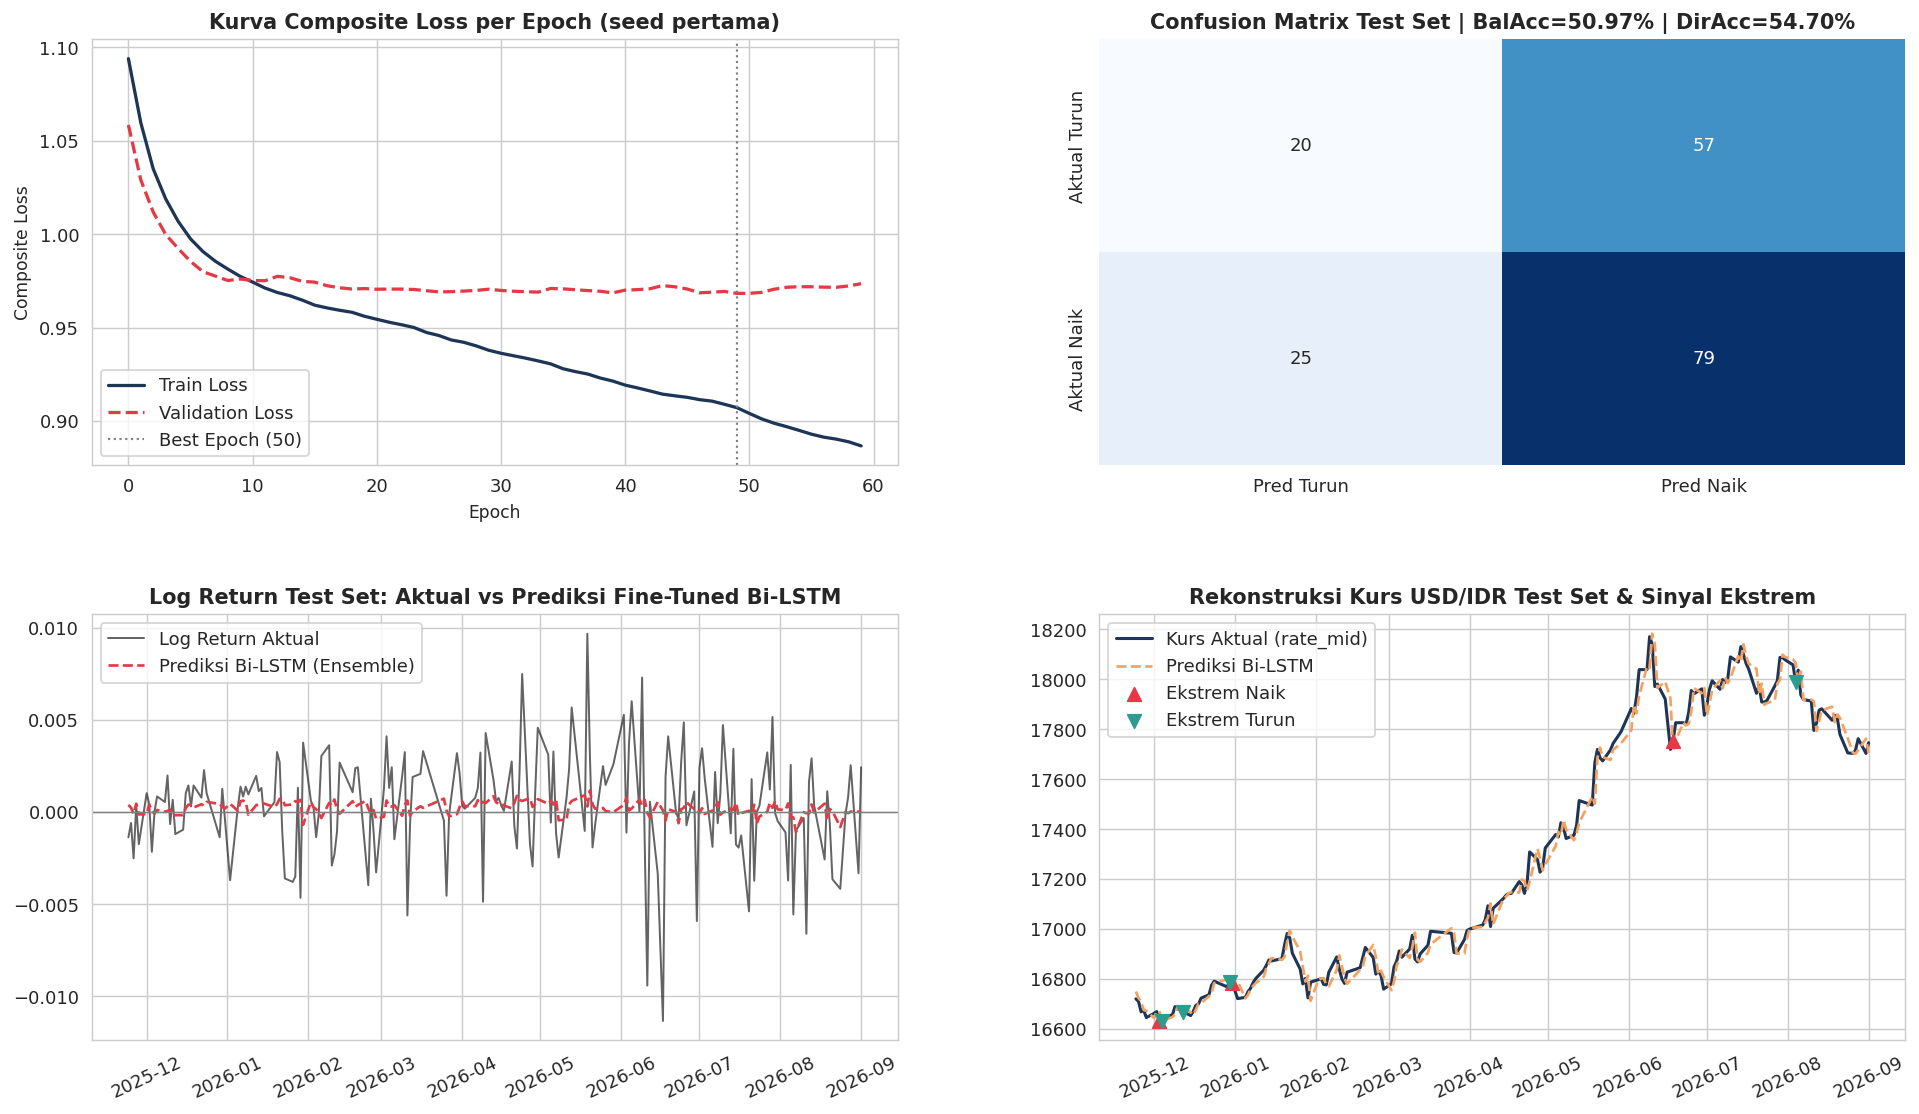

,Tanggal,Kurs Aktual,Kurs Prediksi,LogRet Aktual,LogRet Prediksi,Arah Aktual,Arah Prediksi
171,2026-08-18,17836.0,17890.09,-0.002576,0.000452,Turun,Naik
172,2026-08-19,17856.0,17828.22,0.001121,-0.000436,Naik,Turun
173,2026-08-20,17844.0,17858.88,-0.000672,0.000161,Turun,Naik
174,2026-08-21,17779.0,17844.81,-0.003649,0.000046,Turun,Naik
175,2026-08-24,17705.0,17764.42,-0.004171,-0.000820,Turun,Turun
176,2026-08-26,17703.0,17705.07,-0.000113,0.000004,Turun,Naik
177,2026-08-27,17717.0,17701.84,0.000791,-0.000065,Naik,Turun
178,2026-08-28,17762.0,17717.37,0.002537,0.000021,Naik,Naik
179,2026-08-31,17703.0,17762.19,-0.003327,0.000011,Turun,Naik
180,2026-09-01,17746.0,17704.55,0.002426,0.000088,Naik,Naik


In [11]:
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# 1. Kurva Composite Loss Train vs Val
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(res_best["tr_hist"], label="Train Loss", color="#1d3557", lw=1.8)
ax1.plot(res_best["va_hist"], label="Validation Loss", color="#e63946", linestyle="--", lw=1.8)
ax1.axvline(max(res_best["best_epoch"] - 1, 0), color="gray", linestyle=":", lw=1.2, label=f"Best Epoch ({res_best['best_epoch']})")
ax1.set_title("Kurva Composite Loss per Epoch (seed pertama)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Composite Loss")
ax1.legend()

# 2. Confusion Matrix Prediksi Arah (Test Set)
ax2 = fig.add_subplot(gs[0, 1])
cm = confusion_matrix(y_te_dir_true, y_te_dir_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred Turun", "Pred Naik"],
            yticklabels=["Aktual Turun", "Aktual Naik"], ax=ax2)
ax2.set_title(
    f"Confusion Matrix Test Set | BalAcc={eval_summary_df.loc[TEST_ROW_LABEL, 'BalAcc (%)']:.2f}% "
    f"| DirAcc={eval_summary_df.loc[TEST_ROW_LABEL, 'DirAcc (%)']:.2f}%"
)

# 3. Deret Waktu Log Return Aktual vs Prediksi (Test Set)
te_dates = seq_data["dates"][te_m]
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(te_dates, y_te_true, label="Log Return Aktual", color="#222222", alpha=0.7, lw=1.1)
ax3.plot(te_dates, res_best["pred_te"], label="Prediksi Bi-LSTM (Ensemble)", color="#e63946", linestyle="--", lw=1.5)
ax3.axhline(0, color="gray", lw=0.8)
ax3.set_title("Log Return Test Set: Aktual vs Prediksi Fine-Tuned Bi-LSTM")
ax3.tick_params(axis="x", rotation=25)
ax3.legend()

# 4. Rekonstruksi Kurs USD/IDR + Sinyal Sentimen Ekstrem (Test Set)
ax4 = fig.add_subplot(gs[1, 1])
prev_r = seq_data["prev_rate"][te_m]
curr_r = seq_data["curr_rate"][te_m]
pred_r = prev_r * np.exp(res_best["pred_te"])
ax4.plot(te_dates, curr_r, label="Kurs Aktual (rate_mid)", color="#1d3557", lw=1.7)
ax4.plot(te_dates, pred_r, label="Prediksi Bi-LSTM", color="#f4a261", linestyle="--", lw=1.5)

te_align = df_model.loc[df_model[date_col].isin(te_dates)].copy()
ex_up = te_align[te_align["flag_naik_ekstrem"] == 1]
ex_dn = te_align[te_align["flag_turun_ekstrem"] == 1]
ax4.scatter(ex_up[date_col], ex_up["rate_mid"], marker="^", s=55, color="#e63946", zorder=5, label="Ekstrem Naik")
ax4.scatter(ex_dn[date_col], ex_dn["rate_mid"], marker="v", s=55, color="#2a9d8f", zorder=5, label="Ekstrem Turun")
ax4.set_title("Rekonstruksi Kurs USD/IDR Test Set & Sinyal Ekstrem")
ax4.tick_params(axis="x", rotation=25)
ax4.legend()

plt.tight_layout()
plt.show()

# Tabel ringkas hasil prediksi 10 hari terakhir di Test Set
pred_test_df = pd.DataFrame({
    "Tanggal": te_dates,
    "Kurs Aktual": np.round(curr_r, 2),
    "Kurs Prediksi": np.round(pred_r, 2),
    "LogRet Aktual": np.round(y_te_true, 6),
    "LogRet Prediksi": np.round(res_best["pred_te"], 6),
    "Arah Aktual": np.where(y_te_dir_true == 1, "Naik", "Turun"),
    "Arah Prediksi": np.where(y_te_dir_pred == 1, "Naik", "Turun"),
})
display(pred_test_df.tail(10))

## 11. Ablation Study per Grup Fitur (Stage 2 Bi-LSTM)

Empat skenario: **Full**, **leave-one-group-out**, **single-group-only**, dan **TS + satu grup**. Setiap skenario dilatih dengan 3 seed lalu dirata-rata (metrik per seed, bukan prediksi ensemble). Pilih grup berdasarkan kolom **Val**; kolom Test hanya untuk pelaporan. Stage 1 tidak dilatih ulang: output `pred_dir_prob` hanya masuk lewat grup `Sent×Arah`.

In [1]:
GROUPS = {
    f"TS ({len(GRP_TS)})": GRP_TS,
    f"BERT-Title ({len(GRP_BERT_TITLE)})": GRP_BERT_TITLE,
    f"FinBERT-Sent ({len(GRP_FINBERT_SENT)})": GRP_FINBERT_SENT,
    f"Sent×Arah ({len(GRP_SENT_INTER)})": GRP_SENT_INTER,
    f"BERTopic ({len(GRP_BERTOPIC)})": GRP_BERTOPIC,
}
ABL_SEEDS = (42, 7, 123)

def eval_reg_raw(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    dt, dp = (y_true > 0).astype(int), (y_pred > 0).astype(int)
    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "DirAcc (%)": float(accuracy_score(dt, dp) * 100),
        "BalAcc (%)": float(balanced_accuracy_score(dt, dp) * 100),
        "F1-Macro (%)": float(f1_score(dt, dp, average="macro") * 100),
    }

def run_cfg(cols, seeds=ABL_SEEDS):
    sd = build_sequences(df_model, cols, BEST_SEQ_LEN)
    s_ = sd["split"]
    tr, va, te = s_ == "train", s_ == "val", s_ == "test"
    yv, yt = sd["y_raw"][va], sd["y_raw"][te]
    va_rows, te_rows = [], []
    for s in seeds:
        r = train_pytorch_regressor(
            make_lstm(len(cols)), sd["X"][tr], sd["y_s"][tr], sd["X"][va], sd["y_s"][va], sd["X"][te],
            sd["mu_y"], sd["std_y"], lr=BEST_CFG["lr"], weight_decay=BEST_CFG["weight_decay"],
            dir_lambda=BEST_CFG["dir_lambda"], batch_size=BEST_CFG["batch_size"],
            epochs=BEST_CFG["epochs"], patience=BEST_CFG["patience"], seed=s)
        va_rows.append(eval_reg_raw(yv, r["pred_va"]))
        te_rows.append(eval_reg_raw(yt, r["pred_te"]))
    va_df = pd.DataFrame(va_rows)
    te_df = pd.DataFrame(te_rows)
    return va_df.mean(), te_df.mean(), te_df.std()

records = []
def add(name, cols, kind):
    v, t, t_sd = run_cfg(cols)
    records.append({
        "Skenario": name, "Tipe": kind, "#Fitur": len(cols),
        "Val BalAcc": v["BalAcc (%)"], "Val RMSE": v["RMSE"],
        "Test BalAcc": t["BalAcc (%)"], "Test BalAcc±sd": t_sd["BalAcc (%)"],
        "Test DirAcc": t["DirAcc (%)"], "Test F1-Macro": t["F1-Macro (%)"],
        "Test RMSE": t["RMSE"], "Test R2": t["R2"],
    })

# 1) Full model
FULL_NAME = f"Full ({len(BEST_COLS)} fitur)"
add(FULL_NAME, BEST_COLS, "full")

# 2) Leave-one-group-out
for g, cols in GROUPS.items():
    keep = [c for c in BEST_COLS if c not in cols]
    add(f"– {g}", keep, "drop-one")

# 3) Single-group-only
for g, cols in GROUPS.items():
    add(f"Only {g}", cols, "only-one")

# 4) Inkremental: TS + grup lain satu per satu
for g, cols in GROUPS.items():
    if g.startswith("TS ("):
        continue
    add(f"TS + {g}", GRP_TS + cols, "TS+one")

abl_df = pd.DataFrame(records).set_index("Skenario")
full = abl_df.loc[FULL_NAME]
abl_df["Δ Test BalAcc vs Full"] = abl_df["Test BalAcc"] - full["Test BalAcc"]
abl_df["Δ Val BalAcc vs Full"] = abl_df["Val BalAcc"] - full["Val BalAcc"]
with pd.option_context("display.precision", 8, "display.float_format", None):
    display(abl_df)

# Plot Δ BalAcc untuk drop-one
d = abl_df[abl_df["Tipe"] == "drop-one"]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(d)); w = 0.38
ax.bar(x - w/2, d["Δ Val BalAcc vs Full"], w, label="Val", color="#1d3557")
ax.bar(x + w/2, d["Δ Test BalAcc vs Full"], w, label="Test", color="#e63946")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(d.index, rotation=20, ha="right")
ax.set_ylabel("Δ BalAcc (poin) vs Full")
ax.set_title("Ablasi Leave-One-Group-Out (mean 3 seed)")
ax.legend(); plt.tight_layout(); plt.show()


                           Tipe  #Fitur     Val BalAcc      Val RMSE    Test BalAcc  Test BalAcc±sd    Test DirAcc  Test F1-Macro     Test RMSE       Test R2  Δ Test BalAcc vs Full  Δ Val BalAcc vs Full
Skenario                                                                                                                                                                                                  
Full (32 fitur)            full      32  54.5882936508  0.0033265784  54.1916416916    1.2844748663  56.7219152855  53.7756654386  0.0029104876 -0.0187150637           0.0000000000      0.0000000000e+00
– TS (14)              drop-one      18  51.8353174603  0.0033680797  55.2343489843    1.6021815931  57.2744014733  55.0539794423  0.0028856719 -0.0013908545           1.0427072927     -2.7529761905e+00
– BERT-Title (4)       drop-one      28  53.4970238095  0.0033278181  50.6660006660    2.0572047737  52.6703499079  50.2769041935  0.0028858152 -0.0014936924          -3.5256410256     -1.